# Optimización de rutas del Metro de la CDMX mediante Colonia de Hormigas (ACO)



En este proyecto se implementará el algoritmo de **Optimización por Colonia de Hormigas** para encontrar rutas eficientes dentro de la red del Metro de la Ciudad de México.

El Metro se representará mediante un grafo ponderado, donde las estaciones constituyen los nodos y las conexiones entre ellas tienen como peso la distancia en metros.

A diferencia de una búsqueda basada únicamente en la distancia, consideraremos también el número de transbordos necesarios para llegar al destino. Para ello, utilizaremos la función objetivo:

$$
C(R)=D(R)+\lambda T(R)
$$

Donde:

- \(D(R)\): distancia total recorrida en metros.
- \(T(R)\): número de transbordos realizados.
- \(\lambda\): penalización asignada a cada transbordo, en metros equivalentes.


**Caso de estudio:** Cuatro Caminos → Pantitlán.

## 1. Construcción y validación del grafo

Partiremos de un diccionario que contiene las conexiones entre estaciones del Metro de la CDMX y sus distancias en metros.

Antes de implementar los algoritmos, verificaremos que las conexiones sean válidas, que las distancias sean consistentes y que la red permita identificar correctamente los cambios de línea.

In [33]:
metro_cdmx = {
    # Línea 1
    "Observatorio": {
        "Tacubaya": 1262
    },

    "Tacubaya": {
        "Observatorio": 1262,
        "Juanacatlán": 1158,
        "Constituyentes": 1005,
        "San Pedro de los Pinos": 1084,
        "Patriotismo": 1133
    },

    "Juanacatlán": {
        "Tacubaya": 1158,
        "Chapultepec": 973
    },

    "Chapultepec": {
        "Juanacatlán": 973,
        "Sevilla": 501
    },

    "Sevilla": {
        "Chapultepec": 501,
        "Insurgentes": 645
    },

    "Insurgentes": {
        "Sevilla": 645,
        "Cuauhtémoc": 793
    },

    "Cuauhtémoc": {
        "Insurgentes": 793,
        "Balderas": 409
    },

    "Balderas": {
        "Cuauhtémoc": 409,
        "Salto del Agua": 458,
        "Juárez": 659,
        "Niños Héroes": 665
    },

    "Salto del Agua": {
        "Balderas": 458,
        "Isabel la Católica": 445,
        "San Juan de Letrán": 292,
        "Doctores": 564
    },

    "Isabel la Católica": {
        "Salto del Agua": 445,
        "Pino Suárez": 382
    },

    "Pino Suárez": {
        "Isabel la Católica": 382,
        "Merced": 745,
        "Zócalo/Tenochtitlan": 745,
        "San Antonio Abad": 817
    },

    "Merced": {
        "Pino Suárez": 745,
        "Candelaria": 698
    },

    "Candelaria": {
        "Merced": 698,
        "San Lázaro": 866,
        "Fray Servando": 633,
        "Morelos": 1062
    },

    "San Lázaro": {
        "Candelaria": 866,
        "Moctezuma": 478,
        "Ricardo Flores Magón": 907,
        "Morelos": 1296
    },

    "Moctezuma": {
        "San Lázaro": 478,
        "Balbuena": 703
    },

    "Balbuena": {
        "Moctezuma": 703,
        "Boulevard Puerto Aéreo": 595
    },

    "Boulevard Puerto Aéreo": {
        "Balbuena": 595,
        "Gómez Farías": 611
    },

    "Gómez Farías": {
        "Boulevard Puerto Aéreo": 611,
        "Zaragoza": 762
    },

    "Zaragoza": {
        "Gómez Farías": 762,
        "Pantitlán": 1320
    },

    "Pantitlán": {
        "Zaragoza": 1320,
        "Hangares": 1644,
        "Puebla": 1380,
        "Agrícola Oriental": 1409
    },


    # Línea 2
    "Cuatro Caminos": {
        "Panteones": 1639
    },

    "Panteones": {
        "Cuatro Caminos": 1639,
        "Tacuba": 1416
    },

    "Tacuba": {
        "Panteones": 1416,
        "Cuitláhuac": 637,
        "Refinería": 1295,
        "San Joaquín": 1433
    },

    "Cuitláhuac": {
        "Tacuba": 637,
        "Popotla": 620
    },

    "Popotla": {
        "Cuitláhuac": 620,
        "Colegio Militar": 462
    },

    "Colegio Militar": {
        "Popotla": 462,
        "Normal": 516
    },

    "Normal": {
        "Colegio Militar": 516,
        "San Cosme": 657
    },

    "San Cosme": {
        "Normal": 657,
        "Revolución": 537
    },

    "Revolución": {
        "San Cosme": 537,
        "Hidalgo": 587
    },

    "Hidalgo": {
    "Revolución": 587,
    "Bellas Artes": 447,
    "Guerrero": 702,
    "Juárez": 251
    },

    "Bellas Artes": {
        "Hidalgo": 447,
        "Allende": 387,
        "Garibaldi/Lagunilla": 634,
        "San Juan de Letrán": 456
    },

    "Allende": {
        "Bellas Artes": 387,
        "Zócalo/Tenochtitlan": 602
    },

    "Zócalo/Tenochtitlan": {
        "Allende": 602,
        "Pino Suárez": 745
    },

    "San Antonio Abad": {
        "Pino Suárez": 817,
        "Chabacano": 642
    },

    "Chabacano": {
        "San Antonio Abad": 642,
        "Viaducto": 774,
        "Obrera": 1143,
        "La Viga": 843,
        "Lázaro Cárdenas": 1000,
        "Jamaica": 1031
    },

    "Viaducto": {
        "Chabacano": 774,
        "Xola": 490
    },

    "Xola": {
        "Viaducto": 490,
        "Villa de Cortés": 698
    },

    "Villa de Cortés": {
        "Xola": 698,
        "Nativitas": 750
    },

    "Nativitas": {
        "Villa de Cortés": 750,
        "Portales": 924
    },

    "Portales": {
        "Nativitas": 924,
        "Ermita": 748
    },

    "Ermita": {
        "Portales": 748,
        "General Anaya": 838,
        "Mexicaltzingo": 1805,
        "Eje Central": 895
    },

    "General Anaya": {
        "Ermita": 838,
        "Tasqueña": 1330
    },

    "Tasqueña": {
        "General Anaya": 1330
    },

    # Línea 3

    "Indios Verdes": {
        "Deportivo 18 de Marzo": 1166
    },

    "Deportivo 18 de Marzo": {
        "Indios Verdes": 1166,
        "Potrero": 966,
        "Lindavista": 1075,
        "La Villa - Basílica": 570,
    },

    "Potrero": {
        "Deportivo 18 de Marzo": 966,
        "La Raza": 1106
    },

    "La Raza": {
        "Potrero": 1106,
        "Tlatelolco": 1445,
        "Autobuses del Norte": 975,
        "Misterios": 892
    },

    "Tlatelolco": {
        "La Raza": 1445,
        "Guerrero": 1042
    },

    "Guerrero": {
        "Tlatelolco": 1042,
        "Hidalgo": 702,
        "Garibaldi/Lagunilla": 757,
        "Buenavista": 521
    },

    "Juárez": {
        "Hidalgo": 251,
        "Balderas": 659
    },

    "Niños Héroes": {
        "Balderas": 665,
        "Hospital General": 559
    },

    "Hospital General": {
        "Niños Héroes": 559,
        "Centro Médico": 653
    },

    "Centro Médico": {
        "Hospital General": 653,
        "Etiopía/Plaza de la Transparencia": 1119,
        "Chilpancingo": 1152,
        "Lázaro Cárdenas": 1059
    },

    "Etiopía/Plaza de la Transparencia": {
        "Centro Médico": 1119,
        "Eugenia": 950
    },

    "Eugenia": {
        "Etiopía/Plaza de la Transparencia": 950,
        "División del Norte": 715
    },

    "División del Norte": {
        "Eugenia": 715,
        "Zapata": 794
    },

    "Zapata": {
        "División del Norte": 794,
        "Coyoacán": 1153,
        "Parque de los Venados": 563,
        "Hospital 20 de Noviembre": 450
    },

    "Coyoacán": {
        "Zapata": 1153,
        "Viveros/Derechos Humanos": 908
    },

    "Viveros/Derechos Humanos": {
        "Coyoacán": 908,
        "Miguel Ángel de Quevedo": 824
    },

    "Miguel Ángel de Quevedo": {
        "Viveros/Derechos Humanos": 824,
        "Copilco": 1295
    },

    "Copilco": {
        "Miguel Ángel de Quevedo": 1295,
        "Universidad": 1306
    },

    "Universidad": {
        "Copilco": 1306
    },

    # Línea 4

    "Santa Anita": {
        "Jamaica": 758,
        "La Viga": 633,
        "Coyuya": 968
    },

    "Jamaica": {
        "Santa Anita": 758,
        "Fray Servando": 1033,
        "Chabacano": 1031,
        "Mixiuhca": 942
    },

    "Fray Servando": {
        "Jamaica": 1033,
        "Candelaria": 633
    },

    "Morelos": {
        "Candelaria": 1062,
        "Canal del Norte": 910,
        "San Lázaro": 1296,
        "Tepito": 498
    },

    "Canal del Norte": {
        "Morelos": 910,
        "Consulado": 884
    },

    "Consulado": {
        "Canal del Norte": 884,
        "Bondojito": 645,
        "Valle Gómez": 679,
        "Eduardo Molina": 815
    },

    "Bondojito": {
        "Consulado": 645,
        "Talismán": 959
    },

    "Talismán": {
        "Bondojito": 959,
        "Martín Carrera": 1129
    },

    "Martín Carrera": {
        "Talismán": 1129,
        "La Villa - Basílica": 1141
    },

    # Línea 5

    "Politécnico": {
        "Instituto del Petróleo": 1188
    },

    "Instituto del Petróleo": {
        "Politécnico": 1188,
        "Autobuses del Norte": 1067,
        "Vallejo": 755,
        "Lindavista": 1258
    },

    "Autobuses del Norte": {
        "Instituto del Petróleo": 1067,
        "La Raza": 975
    },

    "Misterios": {
        "La Raza": 892,
        "Valle Gómez": 969
    },

    "Valle Gómez": {
        "Misterios": 969,
        "Consulado": 679
    },

    "Eduardo Molina": {
        "Consulado": 815,
        "Aragón": 860
    },

    "Aragón": {
        "Eduardo Molina": 860,
        "Oceanía": 1219
    },

    "Oceanía": {
        "Aragón": 1219,
        "Terminal Aérea": 1174,
        "Deportivo Oceanía": 863,
        "Romero Rubio": 809
    },

    "Terminal Aérea": {
        "Oceanía": 1174,
        "Hangares": 1153
    },

    "Hangares": {
        "Terminal Aérea": 1153,
        "Pantitlán": 1644
    },

    # Línea 6

    "El Rosario": {
        "Tezozómoc": 1257,
        "Aquiles Serdán": 1615
    },

    "Tezozómoc": {
        "El Rosario": 1257,
        "Azcapotzalco": 973
    },

    "Azcapotzalco": {
        "Tezozómoc": 973,
        "Ferrería": 1173
    },

    "Ferrería": {
        "Azcapotzalco": 1173,
        "Norte 45": 1072
    },

    "Norte 45": {
        "Ferrería": 1072,
        "Vallejo": 660
    },

    "Vallejo": {
        "Norte 45": 660,
        "Instituto del Petróleo": 755
    },

    "Lindavista": {
        "Instituto del Petróleo": 1258,
        "Deportivo 18 de Marzo": 1075
    },

    "La Villa - Basílica": {
        "Deportivo 18 de Marzo": 570,
        "Martín Carrera": 1141
    },

    # Línea 7

    "Aquiles Serdán": {
        "El Rosario": 1615,
        "Camarones": 1402
    },

    "Camarones": {
        "Aquiles Serdán": 1402,
        "Refinería": 952
    },

    "Refinería": {
        "Camarones": 952,
        "Tacuba": 1295
    },

    "San Joaquín": {
        "Tacuba": 1433,
        "Polanco": 1163
    },

    "Polanco": {
        "San Joaquín": 1163,
        "Auditorio": 812
    },

    "Auditorio": {
        "Polanco": 812,
        "Constituyentes": 1430
    },

    "Constituyentes": {
        "Auditorio": 1430,
        "Tacubaya": 1005
    },

    "San Pedro de los Pinos": {
        "Tacubaya": 1084,
        "San Antonio": 606
    },

    "San Antonio": {
        "San Pedro de los Pinos": 606,
        "Mixcoac": 788
    },

    "Mixcoac": {
        "San Antonio": 788,
        "Barranca del Muerto": 1476,
        "Insurgentes Sur": 651
    },

    "Barranca del Muerto": {
        "Mixcoac": 1476
    },

    # Línea 8

    "Garibaldi/Lagunilla": {
        "Bellas Artes": 634,
        "Lagunilla": 474,
        "Guerrero": 757
    },

    "San Juan de Letrán": {
        "Bellas Artes": 456,
        "Salto del Agua": 292
    },

    "Doctores": {
        "Salto del Agua": 564,
        "Obrera": 761
    },

    "Obrera": {
        "Doctores": 761,
        "Chabacano": 1143
    },

    "La Viga": {
        "Chabacano": 843,
        "Santa Anita": 633
    },

    "Coyuya": {
        "Santa Anita": 968,
        "Iztacalco": 993
    },

    "Iztacalco": {
        "Coyuya": 993,
        "Apatlaco": 910
    },

    "Apatlaco": {
        "Iztacalco": 910,
        "Aculco": 534
    },

    "Aculco": {
        "Apatlaco": 534,
        "Escuadrón 201": 789
    },

    "Escuadrón 201": {
        "Aculco": 789,
        "Atlalilco": 1738
    },

    "Atlalilco": {
        "Escuadrón 201": 1738,
        "Iztapalapa": 732,
        "Culhuacán": 1671,
        "Mexicaltzingo": 1922
    },

    "Iztapalapa": {
        "Atlalilco": 732,
        "Cerro de la Estrella": 717
    },

    "Cerro de la Estrella": {
        "Iztapalapa": 717,
        "UAM-I": 1135
    },

    "UAM-I": {
        "Cerro de la Estrella": 1135,
        "Constitución de 1917": 1137
    },

    "Constitución de 1917": {
        "UAM-I": 1137
    },

    # Línea 9

    "Patriotismo": {
        "Tacubaya": 1133,
        "Chilpancingo": 955
    },

    "Chilpancingo": {
        "Patriotismo": 955,
        "Centro Médico": 1152
    },

    "Lázaro Cárdenas": {
        "Centro Médico": 1059,
        "Chabacano": 1000
    },

    "Mixiuhca": {
        "Jamaica": 942,
        "Velódromo": 821
    },

    "Velódromo": {
        "Mixiuhca": 821,
        "Ciudad Deportiva": 1110
    },

    "Ciudad Deportiva": {
        "Velódromo": 1110,
        "Puebla": 800
    },

    "Puebla": {
        "Ciudad Deportiva": 800,
        "Pantitlán": 1380
    },

    # Línea A

    "Agrícola Oriental": {
        "Pantitlán": 1409,
        "Canal de San Juan": 1093
    },

    "Canal de San Juan": {
        "Agrícola Oriental": 1093,
        "Tepalcates": 1456
    },

    "Tepalcates": {
        "Canal de San Juan": 1456,
        "Guelatao": 1161
    },

    "Guelatao": {
        "Tepalcates": 1161,
        "Peñón Viejo": 2206
    },

    "Peñón Viejo": {
        "Guelatao": 2206,
        "Acatitla": 1379
    },

    "Acatitla": {
        "Peñón Viejo": 1379,
        "Santa Marta": 1100
    },

    "Santa Marta": {
        "Acatitla": 1100,
        "Los Reyes": 1783
    },

    "Los Reyes": {
        "Santa Marta": 1783,
        "La Paz": 1956
    },

    "La Paz": {
        "Los Reyes": 1956
    },

    # Línea B

    "Ciudad Azteca": {
        "Plaza Aragón": 574
    },

    "Plaza Aragón": {
        "Ciudad Azteca": 574,
        "Olímpica": 709
    },

    "Olímpica": {
        "Plaza Aragón": 709,
        "Ecatepec": 596
    },

    "Ecatepec": {
        "Olímpica": 596,
        "Múzquiz": 1485
    },

    "Múzquiz": {
        "Ecatepec": 1485,
        "Río de los Remedios": 1155
    },

    "Río de los Remedios": {
        "Múzquiz": 1155,
        "Impulsora": 436
    },

    "Impulsora": {
        "Río de los Remedios": 436,
        "Nezahualcóyotl": 1393
    },

    "Nezahualcóyotl": {
        "Impulsora": 1393,
        "Villa de Aragón": 1335
    },

    "Villa de Aragón": {
        "Nezahualcóyotl": 1335,
        "Bosques de Aragón": 784
    },

    "Bosques de Aragón": {
        "Villa de Aragón": 784,
        "Deportivo Oceanía": 1165
    },

    "Deportivo Oceanía": {
        "Bosques de Aragón": 1165,
        "Oceanía": 863
    },

    "Romero Rubio": {
        "Oceanía": 809,
        "Ricardo Flores Magón": 908
    },

    "Ricardo Flores Magón": {
        "Romero Rubio": 908,
        "San Lázaro": 907
    },

    "Tepito": {
        "Morelos": 498,
        "Lagunilla": 611
    },

    "Lagunilla": {
        "Tepito": 611,
        "Garibaldi/Lagunilla": 474
    },

    "Buenavista": {
        "Guerrero": 521
    },

    # Línea 12

    "Tláhuac": {
        "Tlaltenco": 1298
    },

    "Tlaltenco": {
        "Tláhuac": 1298,
        "Zapotitlán": 1115
    },

    "Zapotitlán": {
        "Tlaltenco": 1115,
        "Nopalera": 1276
    },

    "Nopalera": {
        "Zapotitlán": 1276,
        "Olivos": 1360
    },

    "Olivos": {
        "Nopalera": 1360,
        "Tezonco": 490
    },

    "Tezonco": {
        "Olivos": 490,
        "Periférico Oriente": 1545
    },

    "Periférico Oriente": {
        "Tezonco": 1545,
        "Calle 11": 1111
    },

    "Calle 11": {
        "Periférico Oriente": 1111,
        "Lomas Estrella": 906
    },

    "Lomas Estrella": {
        "Calle 11": 906,
        "San Andrés Tomatlán": 1060
    },

    "San Andrés Tomatlán": {
        "Lomas Estrella": 1060,
        "Culhuacán": 990
    },

    "Culhuacán": {
        "San Andrés Tomatlán": 990,
        "Atlalilco": 1671
    },

    "Mexicaltzingo": {
        "Atlalilco": 1922,
        "Ermita": 1805
    },

    "Eje Central": {
        "Ermita": 895,
        "Parque de los Venados": 1280
    },

    "Parque de los Venados": {
        "Eje Central": 1280,
        "Zapata": 563
    },

    "Hospital 20 de Noviembre": {
        "Zapata": 450,
        "Insurgentes Sur": 725
    },

    "Insurgentes Sur": {
        "Hospital 20 de Noviembre": 725,
        "Mixcoac": 651
    }

}

### Identificación de líneas

Para identificar los transbordos, se registra la secuencia de estaciones
de cada línea. Esto permitirá distinguir los desplazamientos dentro de
una misma línea de los cambios entre líneas.


In [34]:
lineas_metro = {
    "L1": [
        "Observatorio", "Tacubaya", "Juanacatlán",
        "Chapultepec", "Sevilla", "Insurgentes",
        "Cuauhtémoc", "Balderas", "Salto del Agua",
        "Isabel la Católica", "Pino Suárez", "Merced",
        "Candelaria", "San Lázaro", "Moctezuma",
        "Balbuena", "Boulevard Puerto Aéreo",
        "Gómez Farías", "Zaragoza", "Pantitlán"
    ],

    "L2": [
        "Cuatro Caminos", "Panteones", "Tacuba",
        "Cuitláhuac", "Popotla", "Colegio Militar",
        "Normal", "San Cosme", "Revolución",
        "Hidalgo", "Bellas Artes", "Allende",
        "Zócalo/Tenochtitlan", "Pino Suárez",
        "San Antonio Abad", "Chabacano",
        "Viaducto", "Xola", "Villa de Cortés",
        "Nativitas", "Portales", "Ermita",
        "General Anaya", "Tasqueña"
    ],

    "L3": [
        "Indios Verdes", "Deportivo 18 de Marzo",
        "Potrero", "La Raza", "Tlatelolco",
        "Guerrero", "Hidalgo", "Juárez",
        "Balderas", "Niños Héroes", "Hospital General",
        "Centro Médico", "Etiopía/Plaza de la Transparencia",
        "Eugenia", "División del Norte", "Zapata",
        "Coyoacán", "Viveros/Derechos Humanos",
        "Miguel Ángel de Quevedo", "Copilco",
        "Universidad"
    ],

        "L4": [
        "Santa Anita", "Jamaica", "Fray Servando",
        "Candelaria", "Morelos", "Canal del Norte",
        "Consulado", "Bondojito", "Talismán",
        "Martín Carrera"
    ],

    "L5": [
        "Politécnico", "Instituto del Petróleo",
        "Autobuses del Norte", "La Raza", "Misterios",
        "Valle Gómez", "Consulado", "Eduardo Molina",
        "Aragón", "Oceanía", "Terminal Aérea",
        "Hangares", "Pantitlán"
    ],

    "L6": [
        "El Rosario", "Tezozómoc", "Azcapotzalco",
        "Ferrería", "Norte 45", "Vallejo",
        "Instituto del Petróleo", "Lindavista",
        "Deportivo 18 de Marzo", "La Villa - Basílica",
        "Martín Carrera"
    ],

    "L7": [
        "El Rosario", "Aquiles Serdán", "Camarones",
        "Refinería", "Tacuba", "San Joaquín",
        "Polanco", "Auditorio", "Constituyentes",
        "Tacubaya", "San Pedro de los Pinos",
        "San Antonio", "Mixcoac", "Barranca del Muerto"
    ],

    "L8": [
        "Garibaldi/Lagunilla", "Bellas Artes",
        "San Juan de Letrán", "Salto del Agua",
        "Doctores", "Obrera", "Chabacano",
        "La Viga", "Santa Anita", "Coyuya",
        "Iztacalco", "Apatlaco", "Aculco",
        "Escuadrón 201", "Atlalilco", "Iztapalapa",
        "Cerro de la Estrella", "UAM-I",
        "Constitución de 1917"
    ],

    "L9": [
        "Tacubaya", "Patriotismo", "Chilpancingo",
        "Centro Médico", "Lázaro Cárdenas",
        "Chabacano", "Jamaica", "Mixiuhca",
        "Velódromo", "Ciudad Deportiva",
        "Puebla", "Pantitlán"
    ],

    "LA": [
        "Pantitlán", "Agrícola Oriental",
        "Canal de San Juan", "Tepalcates", "Guelatao",
        "Peñón Viejo", "Acatitla", "Santa Marta",
        "Los Reyes", "La Paz"
    ],

    "LB": [
        "Ciudad Azteca", "Plaza Aragón", "Olímpica",
        "Ecatepec", "Múzquiz", "Río de los Remedios",
        "Impulsora", "Nezahualcóyotl",
        "Villa de Aragón", "Bosques de Aragón",
        "Deportivo Oceanía", "Oceanía",
        "Romero Rubio", "Ricardo Flores Magón",
        "San Lázaro", "Morelos", "Tepito",
        "Lagunilla", "Garibaldi/Lagunilla",
        "Guerrero", "Buenavista"
    ],

    "L12": [
        "Tláhuac", "Tlaltenco", "Zapotitlán",
        "Nopalera", "Olivos", "Tezonco",
        "Periférico Oriente", "Calle 11",
        "Lomas Estrella", "San Andrés Tomatlán",
        "Culhuacán", "Atlalilco", "Mexicaltzingo",
        "Ermita", "Eje Central", "Parque de los Venados",
        "Zapata", "Hospital 20 de Noviembre",
        "Insurgentes Sur", "Mixcoac"
    ]
}

### Identificación de líneas y validación de conexiones

El diccionario metro_cdmx fue recuperado de un proyecto anterior de búsqueda de rutas, donde se representaban las estaciones y sus distancias mediante un grafo ponderado.

Para este proyecto es necesario ampliar dicha representación, ya que además de la distancia buscamos considerar el número de transbordos.

Por ello, incorporamos el diccionario lineas_metro, que identifica las estaciones pertenecientes a cada línea. Posteriormente, verificamos que sus estaciones y conexiones coincidan con el grafo original.


In [35]:
print("VALIDACIÓN DE LAS LÍNEAS DEL METRO\n")

for linea, estaciones in lineas_metro.items():

    faltantes = [
        estacion for estacion in estaciones
        if estacion not in metro_cdmx
    ]

    conexiones_faltantes = [
        (origen, destino)
        for origen, destino in zip(estaciones, estaciones[1:])
        if origen not in metro_cdmx
        or destino not in metro_cdmx[origen]
    ]

    estado = "OK" if not faltantes and not conexiones_faltantes else "REVISAR"

    print(f"{linea}: {len(estaciones)} estaciones | {estado}")

    if faltantes:
        print("  Estaciones faltantes:", faltantes)

    if conexiones_faltantes:
        print("  Conexiones faltantes:", conexiones_faltantes)
    

VALIDACIÓN DE LAS LÍNEAS DEL METRO

L1: 20 estaciones | OK
L2: 24 estaciones | OK
L3: 21 estaciones | OK
L4: 10 estaciones | OK
L5: 13 estaciones | OK
L6: 11 estaciones | OK
L7: 14 estaciones | OK
L8: 19 estaciones | OK
L9: 12 estaciones | OK
LA: 10 estaciones | OK
LB: 21 estaciones | OK
L12: 20 estaciones | OK


In [36]:
# Identificar las líneas a las que pertenece cada estación
estaciones_lineas = {}

for linea, estaciones in lineas_metro.items():
    for estacion in estaciones:
        if estacion not in estaciones_lineas:
            estaciones_lineas[estacion] = []

        estaciones_lineas[estacion].append(linea)

# Seleccionar estaciones con más de una línea
correspondencias = {
    estacion: lineas
    for estacion, lineas in estaciones_lineas.items()
    if len(lineas) > 1
}

print(f"Estaciones de correspondencia: {len(correspondencias)}\n")

for estacion, lineas in sorted(correspondencias.items()):
    print(f"{estacion}: {', '.join(lineas)}")

Estaciones de correspondencia: 28

Atlalilco: L8, L12
Balderas: L1, L3
Bellas Artes: L2, L8
Candelaria: L1, L4
Centro Médico: L3, L9
Chabacano: L2, L8, L9
Consulado: L4, L5
Deportivo 18 de Marzo: L3, L6
El Rosario: L6, L7
Ermita: L2, L12
Garibaldi/Lagunilla: L8, LB
Guerrero: L3, LB
Hidalgo: L2, L3
Instituto del Petróleo: L5, L6
Jamaica: L4, L9
La Raza: L3, L5
Martín Carrera: L4, L6
Mixcoac: L7, L12
Morelos: L4, LB
Oceanía: L5, LB
Pantitlán: L1, L5, L9, LA
Pino Suárez: L1, L2
Salto del Agua: L1, L8
San Lázaro: L1, LB
Santa Anita: L4, L8
Tacuba: L2, L7
Tacubaya: L1, L7, L9
Zapata: L3, L12


In [37]:
total_por_linea = sum(
    len(estaciones)
    for estaciones in lineas_metro.values()
)

estaciones_unicas = len(estaciones_lineas)

print("Registros por línea:", total_por_linea)
print("Estaciones únicas:", estaciones_unicas)
print("Correspondencias únicas:", len(correspondencias))

Registros por línea: 195
Estaciones únicas: 163
Correspondencias únicas: 28


### Validación de estaciones y correspondencias

Al revisar el grafo, encontramos 163 estaciones únicas y 28 estaciones de correspondencia. Sin embargo, al contar las estaciones por línea, obtenemos un total de 195 registros.

Esta diferencia se debe a que las estaciones compartidas entre varias líneas aparecen repetidas en el conteo por línea, mientras que nuestro diccionario las registra una sola vez.

Para el proyecto utilizaremos las 28 correspondencias identificadas, ya que nos permiten reconocer los puntos donde es posible cambiar de línea y contabilizar los transbordos de cada ruta.

### Construcción del grafo expandido

Para identificar los transbordos, construiremos un nuevo grafo donde cada nodo estará formado por una estación y su línea correspondiente.

Las conexiones entre estaciones de una misma línea conservarán las distancias originales, mientras que los cambios de línea se representarán mediante conexiones adicionales.

In [38]:
# Construcción del grafo expandido
grafo_expandido = {}

# Crear un nodo por cada estación y línea
for linea, estaciones in lineas_metro.items():
    for estacion in estaciones:
        grafo_expandido[(estacion, linea)] = {}

# Agregar conexiones entre estaciones de la misma línea
for linea, estaciones in lineas_metro.items():
    for origen, destino in zip(estaciones, estaciones[1:]):

        distancia = metro_cdmx[origen][destino]

        nodo_origen = (origen, linea)
        nodo_destino = (destino, linea)

        grafo_expandido[nodo_origen][nodo_destino] = (distancia, 0)
        grafo_expandido[nodo_destino][nodo_origen] = (distancia, 0)

# Agregar conexiones de transbordo
for estacion, lineas in correspondencias.items():
    for linea_origen in lineas:
        for linea_destino in lineas:

            if linea_origen != linea_destino:
                nodo_origen = (estacion, linea_origen)
                nodo_destino = (estacion, linea_destino)

                grafo_expandido[nodo_origen][nodo_destino] = (0, 1)

In [39]:
# Contamos nodos y conexiones
numero_nodos = len(grafo_expandido)

numero_conexiones = sum(
    len(vecinos)
    for vecinos in grafo_expandido.values()
) // 2

# Clasificamos conexiones
viajes = 0
transbordos = 0

for nodo, vecinos in grafo_expandido.items():
    for vecino, (distancia, cambio) in vecinos.items():
        if cambio == 0:
            viajes += 1
        else:
            transbordos += 1

print("VALIDACIÓN DEL GRAFO EXPANDIDO\n")
print(f"Nodos: {numero_nodos}")
print(f"Conexiones totales: {numero_conexiones}")
print(f"Conexiones de viaje: {viajes // 2}")
print(f"Conexiones de transbordo: {transbordos // 2}")

VALIDACIÓN DEL GRAFO EXPANDIDO

Nodos: 195
Conexiones totales: 220
Conexiones de viaje: 183
Conexiones de transbordo: 37


In [40]:
# Comprobamos conexiones de una estación de correspondencia
estacion = ("Hidalgo", "L2")

print(f"Conexiones desde {estacion}:\n")

for vecino, (distancia, cambio) in grafo_expandido[estacion].items():

    tipo = "Transbordo" if cambio == 1 else "Viaje"

    print(
        f"{vecino} | {tipo} | "
        f"Distancia: {distancia} m | "
        f"Transbordos: {cambio}"
    )

Conexiones desde ('Hidalgo', 'L2'):

('Revolución', 'L2') | Viaje | Distancia: 587 m | Transbordos: 0
('Bellas Artes', 'L2') | Viaje | Distancia: 447 m | Transbordos: 0
('Hidalgo', 'L3') | Transbordo | Distancia: 0 m | Transbordos: 1


### Validación del grafo expandido

Antes de implementar los algoritmos de búsqueda, hay que comprobar que las conexiones del grafo sean bidireccionales, que sus valores sean consistentes y que todas las estaciones estén conectadas.

Así verificaremos que el modelo pueda utilizarse para buscar rutas entre diferentes estaciones del Metro.

In [41]:
# Verifica conexiones bidireccionales y consistencia
errores = []

for nodo, vecinos in grafo_expandido.items():
    for vecino, valores in vecinos.items():

        if nodo not in grafo_expandido[vecino]:
            errores.append((nodo, vecino, "Sin conexión inversa"))

        elif grafo_expandido[vecino][nodo] != valores:
            errores.append((nodo, vecino, "Valores diferentes"))

# Comprueba conectividad mediante DFS
inicio = next(iter(grafo_expandido))
visitados = set()
pendientes = [inicio]

while pendientes:
    actual = pendientes.pop()

    if actual in visitados:
        continue

    visitados.add(actual)
    pendientes.extend(
        vecino for vecino in grafo_expandido[actual]
        if vecino not in visitados
    )

print("VALIDACIÓN FINAL DEL GRAFO\n")
print(f"Conexiones inconsistentes: {len(errores)}")
print(f"Nodos alcanzables: {len(visitados)}")
print(f"Nodos totales: {len(grafo_expandido)}")

if not errores and len(visitados) == len(grafo_expandido):
    print("\nGrafo validado correctamente.")
else:
    print("\nSe encontraron problemas en el grafo.")

VALIDACIÓN FINAL DEL GRAFO

Conexiones inconsistentes: 0
Nodos alcanzables: 195
Nodos totales: 195

Grafo validado correctamente.


### Función de costo

Para evaluar las rutas, consideraremos tanto la distancia recorrida como el número de transbordos.

Asignaremos inicialmente una penalización de 600 metros equivalentes por cada cambio de línea, tomando como referencia las distancias aproximadas de algunos de los transbordos más largos del Metro.

Este valor será experimental y podrá modificarse posteriormente para analizar su influencia en las rutas encontradas.

In [42]:
# Penalización por transbordo (metros equivalentes)
lambda_transbordo = 600

def evaluar_ruta(ruta, grafo, penalizacion=600):
    distancia_total = 0
    transbordos = 0

    for origen, destino in zip(ruta, ruta[1:]):
        distancia, cambio = grafo[origen][destino]

        distancia_total += distancia
        transbordos += cambio

    costo_total = distancia_total + penalizacion * transbordos

    return distancia_total, transbordos, costo_total

In [43]:
# Ruta para comprobar la función objetivo
ruta_prueba = [
    ("Revolución", "L2"),
    ("Hidalgo", "L2"),
    ("Hidalgo", "L3"),
    ("Juárez", "L3")
]

distancia, transbordos, costo = evaluar_ruta(
    ruta_prueba,
    grafo_expandido,
    lambda_transbordo
)

print("PRUEBA DE LA FUNCIÓN OBJETIVO\n")
print(f"Distancia recorrida: {distancia} m")
print(f"Transbordos realizados: {transbordos}")
print(f"Costo combinado: {costo} m equivalentes")

PRUEBA DE LA FUNCIÓN OBJETIVO

Distancia recorrida: 838 m
Transbordos realizados: 1
Costo combinado: 1438 m equivalentes


## 2. Implementación del algoritmo ACO

### Inicialización de feromonas

El algoritmo comienza asignando una cantidad inicial de feromona a cada conexión del grafo. Utilizaremos un valor uniforme de 1 para que ninguna ruta tenga una ventaja inicial por este factor.

Durante las iteraciones, las feromonas se actualizarán de acuerdo con la calidad de las rutas encontradas por las hormigas.

In [44]:
# Cantidad inicial de feromona
tau_0 = 1.0

# Inicializar feromonas en todas las conexiones
feromonas = {}

for nodo, vecinos in grafo_expandido.items():
    feromonas[nodo] = {}

    for vecino in vecinos:
        feromonas[nodo][vecino] = tau_0

print("INICIALIZACIÓN DE FEROMONAS\n")
print(f"Nodos con feromonas: {len(feromonas)}")

print(f"Conexiones dirigidas: {sum(len(v) for v in feromonas.values())}")

print(f"Feromona inicial: {tau_0}")

INICIALIZACIÓN DE FEROMONAS

Nodos con feromonas: 195
Conexiones dirigidas: 440
Feromona inicial: 1.0


### Información heurística

Además de las feromonas, las hormigas utilizarán información heurística para decidir qué conexiones explorar.

En nuestro modelo, el atractivo de cada conexión será inversamente proporcional a su costo, considerando la distancia en metros y una penalización de 600 metros equivalentes por transbordo.

Así, los movimientos de menor costo tendrán inicialmente mayor probabilidad de ser seleccionados.

In [45]:
# Calcular el atractivo heurístico de cada conexión
heuristica = {}

for nodo, vecinos in grafo_expandido.items():
    heuristica[nodo] = {}

    for vecino, (distancia, cambio) in vecinos.items():

        costo = distancia + lambda_transbordo * cambio

        heuristica[nodo][vecino] = 1 / costo

print("HEURÍSTICA INICIALIZADA\n")
print(f"Nodos: {len(heuristica)}")
print(f"Conexiones dirigidas: {sum(len(v) for v in heuristica.values())}")

HEURÍSTICA INICIALIZADA

Nodos: 195
Conexiones dirigidas: 440


### Probabilidad de transición

Para seleccionar su siguiente movimiento, cada hormiga combina la cantidad de feromona de las conexiones con su atractivo heurístico.

Esta selección es probabilística, por lo que las hormigas pueden explorar diferentes caminos, aunque aquellos con mejores condiciones tendrán mayor probabilidad de ser elegidos.

Utilizaremos inicialmente los parámetros α = 1 y β = 2, dando mayor influencia a la heurística.

In [46]:
# Parámetros iniciales de ACO
alpha = 1
beta = 2

def calcular_probabilidades(nodo_actual, visitados):

    # Vecinos disponibles
    vecinos = [
        vecino
        for vecino in grafo_expandido[nodo_actual]
        if vecino not in visitados
    ]

    if not vecinos:
        return [], []

    # Calcular los pesos de atracción
    pesos = [
        feromonas[nodo_actual][vecino] ** alpha
        * heuristica[nodo_actual][vecino] ** beta
        for vecino in vecinos
    ]

    total = sum(pesos)

    # Normalizar para obtener probabilidades
    probabilidades = [peso / total for peso in pesos]

    return vecinos, probabilidades

In [47]:
nodo_actual = ("Hidalgo", "L2")
visitados = {nodo_actual}

vecinos, probabilidades = calcular_probabilidades(
    nodo_actual, visitados
)

print("PROBABILIDADES DESDE HIDALGO (L2)\n")

for vecino, probabilidad in zip(vecinos, probabilidades):
    print(f"{vecino}: {probabilidad:.2%}")

print(f"\nSuma total: {sum(probabilidades):.4f}")

PROBABILIDADES DESDE HIDALGO (L2)

('Revolución', 'L2'): 27.16%
('Bellas Artes', 'L2'): 46.84%
('Hidalgo', 'L3'): 26.00%

Suma total: 1.0000


### Construcción de rutas

Cada hormiga comenzará en la estación de origen y seleccionará sus movimientos mediante las probabilidades calculadas anteriormente.

Durante el recorrido se evitará visitar nuevamente el mismo nodo para reducir la formación de ciclos. La ruta terminará cuando la hormiga alcance el destino o cuando ya no tenga movimientos disponibles.

Las rutas que lleguen al destino podrán evaluarse posteriormente mediante nuestra función objetivo.

In [48]:
import random

def construir_ruta(origen, destino):

    # Identificar las líneas disponibles en el origen
    lineas_origen = estaciones_lineas[origen]

    # Elegir una línea inicial
    linea_inicial = random.choice(lineas_origen)

    nodo_actual = (origen, linea_inicial)

    ruta = [nodo_actual]
    visitados = {nodo_actual}

    while nodo_actual[0] != destino:

        vecinos, probabilidades = calcular_probabilidades(
            nodo_actual, visitados
        )

        # Si no hay movimientos disponibles, terminar
        if not vecinos:
            return None

        # Elegir el siguiente nodo probabilísticamente
        siguiente = random.choices(
            vecinos,
            weights=probabilidades,
            k=1
        )[0]

        ruta.append(siguiente)
        visitados.add(siguiente)

        nodo_actual = siguiente

    return ruta

In [49]:
random.seed(42)

ruta = construir_ruta("Cuatro Caminos", "Pantitlán")

if ruta is not None:

    distancia, transbordos, costo = evaluar_ruta(
        ruta, grafo_expandido, lambda_transbordo
    )

    print("RUTA ENCONTRADA\n")

    for estacion, linea in ruta:
        print(f"{estacion} ({linea})")

    print(f"\nDistancia: {distancia / 1000:.2f} km")
    print(f"Transbordos: {transbordos}")
    print(f"Costo combinado: {costo / 1000:.2f} km equivalentes")

else:
    print("La hormiga no encontró una ruta.")

La hormiga no encontró una ruta.


In [50]:
random.seed(42)

num_hormigas = 100
rutas_exitosas = 0
rutas_fallidas = 0

for _ in range(num_hormigas):

    ruta = construir_ruta("Cuatro Caminos", "Pantitlán")

    if ruta is not None:
        rutas_exitosas += 1
    else:
        rutas_fallidas += 1

print("PRUEBA DE CONSTRUCCIÓN DE RUTAS\n")
print(f"Hormigas simuladas: {num_hormigas}")
print(f"Rutas exitosas: {rutas_exitosas}")
print(f"Rutas fallidas: {rutas_fallidas}")
print(f"Tasa de éxito: {rutas_exitosas / num_hormigas:.2%}")

PRUEBA DE CONSTRUCCIÓN DE RUTAS

Hormigas simuladas: 100
Rutas exitosas: 17
Rutas fallidas: 83
Tasa de éxito: 17.00%


### Evaporacion de feromonas

In [51]:
# Tasa de evaporación
rho = 0.1

def evaporar_feromonas():

    for nodo in feromonas:
        for vecino in feromonas[nodo]:

            feromonas[nodo][vecino] *= (1 - rho)

### Depósito de feromonas

Las hormigas que consiguen llegar al destino depositan feromonas
sobre las conexiones que utilizaron. La cantidad depositada es
inversamente proporcional al costo de la ruta, de modo que los
recorridos más eficientes reciben un mayor refuerzo.

Las hormigas que no alcanzan el destino no depositan feromonas.

In [52]:
# Cantidad de feromona depositada
Q = 1000

def depositar_feromonas(ruta):

    if ruta is None:
        return

    _, _, costo = evaluar_ruta(
        ruta, grafo_expandido, lambda_transbordo
    )

    deposito = Q / costo

    for origen, destino in zip(ruta, ruta[1:]):

        feromonas[origen][destino] += deposito
        feromonas[destino][origen] += deposito

### Actualización de feromonas

Al terminar cada iteración, primero se evaporan las feromonas
de todas las conexiones. Después, las hormigas que llegaron
al destino refuerzan los caminos que recorrieron.

De esta manera, las rutas de menor costo pueden volverse más
atractivas durante las siguientes iteraciones.

In [53]:
def actualizar_feromonas(rutas_exitosas):

    # Evaporar feromonas
    evaporar_feromonas()

    # Depositar feromonas de las hormigas exitosas
    for ruta in rutas_exitosas:
        depositar_feromonas(ruta)

### Iteraciones del algoritmo ACO

En cada iteración, 100 hormigas intentan encontrar una ruta entre
Cuatro Caminos y Pantitlán.

Las rutas exitosas se evalúan mediante la función objetivo y
se utilizan para actualizar las feromonas.

Repetiremos este proceso durante 50 iteraciones para analizar
la evolución de los costos y la cantidad de hormigas exitosas.

In [54]:
# Parámetros del experimento
num_iteraciones = 50
num_hormigas = 100

# Reiniciar las feromonas
feromonas = {
    nodo: {vecino: tau_0 for vecino in vecinos}
    for nodo, vecinos in grafo_expandido.items()
}

# Fijar semilla para reproducir el experimento
random.seed(42)

# Historial de resultados
historial_costos = []
historial_mejor_global = []
historial_exitosas = []

mejor_ruta_global = None
mejor_costo_global = float("inf")

for iteracion in range(num_iteraciones):

    rutas_exitosas = []
    mejor_costo_iteracion = float("inf")

    # Construcción de rutas
    for _ in range(num_hormigas):

        ruta = construir_ruta("Cuatro Caminos", "Pantitlán")

        if ruta is not None:
            rutas_exitosas.append(ruta)

            _, _, costo = evaluar_ruta(
                ruta, grafo_expandido, lambda_transbordo
            )

            if costo < mejor_costo_iteracion:
                mejor_costo_iteracion = costo

            if costo < mejor_costo_global:
                mejor_costo_global = costo
                mejor_ruta_global = ruta.copy()

    # Actualización de feromonas
    actualizar_feromonas(rutas_exitosas)

    # Guardar resultados
    historial_exitosas.append(len(rutas_exitosas))
    historial_costos.append(
        mejor_costo_iteracion if rutas_exitosas else None
    )
    historial_mejor_global.append(
        mejor_costo_global if mejor_ruta_global else None
    )

    print(
        f"Iteración {iteracion + 1:02d} | "
        f"Exitosas: {len(rutas_exitosas):3d} | "
        f"Mejor costo: "
        f"{mejor_costo_iteracion if rutas_exitosas else 'Sin ruta'}"
    )

print("\nRESULTADO FINAL")

if mejor_ruta_global is not None:
    print("Mejor costo encontrado:", mejor_costo_global)
    print("Nodos recorridos:", len(mejor_ruta_global))
else:
    print("No se encontró ninguna ruta completa.")

Iteración 01 | Exitosas:  17 | Mejor costo: 16630
Iteración 02 | Exitosas:  16 | Mejor costo: 19214
Iteración 03 | Exitosas:  23 | Mejor costo: 16630
Iteración 04 | Exitosas:  23 | Mejor costo: 17995
Iteración 05 | Exitosas:  29 | Mejor costo: 16630
Iteración 06 | Exitosas:  32 | Mejor costo: 16630
Iteración 07 | Exitosas:  29 | Mejor costo: 16630
Iteración 08 | Exitosas:  40 | Mejor costo: 17395
Iteración 09 | Exitosas:  34 | Mejor costo: 16630
Iteración 10 | Exitosas:  41 | Mejor costo: 16630
Iteración 11 | Exitosas:  36 | Mejor costo: 16630
Iteración 12 | Exitosas:  34 | Mejor costo: 16630
Iteración 13 | Exitosas:  39 | Mejor costo: 17995
Iteración 14 | Exitosas:  41 | Mejor costo: 16630
Iteración 15 | Exitosas:  39 | Mejor costo: 16630
Iteración 16 | Exitosas:  44 | Mejor costo: 16630
Iteración 17 | Exitosas:  57 | Mejor costo: 16630
Iteración 18 | Exitosas:  61 | Mejor costo: 16630
Iteración 19 | Exitosas:  50 | Mejor costo: 16630
Iteración 20 | Exitosas:  50 | Mejor costo: 16630


### Análisis de convergencia

Para analizar el comportamiento de ACO, graficaremos la evolución
del mejor costo encontrado en cada iteración y del mejor costo
acumulado.

Esto permitirá observar si el algoritmo encuentra soluciones
más eficientes conforme avanzan las iteraciones.

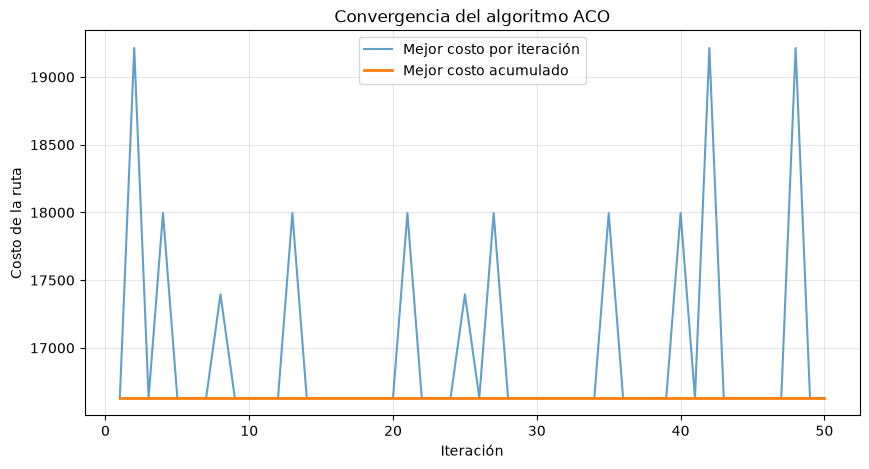

In [55]:
import matplotlib.pyplot as plt

iteraciones = range(1, num_iteraciones + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    iteraciones,
    historial_costos,
    label="Mejor costo por iteración",
    alpha=0.7
)

plt.plot(
    iteraciones,
    historial_mejor_global,
    label="Mejor costo acumulado",
    linewidth=2
)

plt.xlabel("Iteración")
plt.ylabel("Costo de la ruta")
plt.title("Convergencia del algoritmo ACO")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Evolución de hormigas exitosas

Además del costo, analizaremos cuántas hormigas consiguen
completar su recorrido en cada iteración.

Esto nos permitirá observar si la actualización de feromonas
favorece la construcción de rutas que llegan al destino.

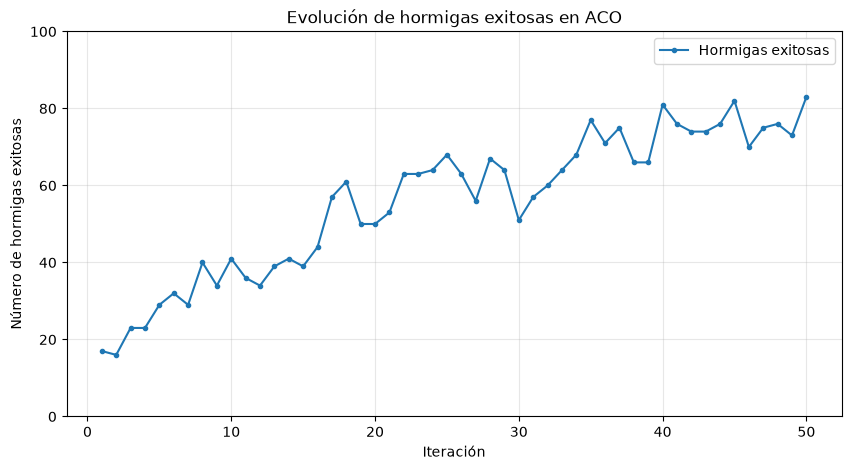

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    iteraciones,
    historial_exitosas,
    marker="o",
    markersize=3,
    label="Hormigas exitosas"
)

plt.xlabel("Iteración")
plt.ylabel("Número de hormigas exitosas")
plt.title("Evolución de hormigas exitosas en ACO")

plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Interpretación de resultados

Durante las 50 iteraciones, la proporción de hormigas que
alcanzaron el destino aumentó del 17 % al 83 %, lo que sugiere
que la actualización de feromonas favoreció las rutas exitosas.

Sin embargo, el mejor costo encontrado permaneció en 16,630.
Por lo tanto, aunque mejoró la efectividad de la búsqueda,
todavía debemos comprobar si la ruta encontrada es óptima.

In [57]:
# Evaluar la mejor ruta encontrada
distancia, transbordos, costo = evaluar_ruta(
    mejor_ruta_global,
    grafo_expandido,
    lambda_transbordo
)

print("MEJOR RUTA ENCONTRADA POR ACO\n")

for i, (estacion, linea) in enumerate(mejor_ruta_global, 1):
    print(f"{i:02d}. {estacion} ({linea})")

print("\nRESUMEN")
print(f"Distancia recorrida: {distancia} metros")
print(f"Transbordos: {transbordos}")
print(f"Penalización: {transbordos * lambda_transbordo} metros")
print(f"Costo total: {costo}")

MEJOR RUTA ENCONTRADA POR ACO

01. Cuatro Caminos (L2)
02. Panteones (L2)
03. Tacuba (L2)
04. Cuitláhuac (L2)
05. Popotla (L2)
06. Colegio Militar (L2)
07. Normal (L2)
08. San Cosme (L2)
09. Revolución (L2)
10. Hidalgo (L2)
11. Bellas Artes (L2)
12. Allende (L2)
13. Zócalo/Tenochtitlan (L2)
14. Pino Suárez (L2)
15. Pino Suárez (L1)
16. Merced (L1)
17. Candelaria (L1)
18. San Lázaro (L1)
19. Moctezuma (L1)
20. Balbuena (L1)
21. Boulevard Puerto Aéreo (L1)
22. Gómez Farías (L1)
23. Zaragoza (L1)
24. Pantitlán (L1)

RESUMEN
Distancia recorrida: 16030 metros
Transbordos: 1
Penalización: 600 metros
Costo total: 16630


In [58]:
import heapq

def dijkstra_metro(grafo, origen, destino, penalizacion=600):

    distancias = {nodo: float("inf") for nodo in grafo}
    anteriores = {}

    distancias[origen] = 0
    cola = [(0, origen)]

    while cola:

        costo_actual, nodo = heapq.heappop(cola)

        if costo_actual > distancias[nodo]:
            continue

        if nodo == destino:
            break

        for vecino, datos in grafo[nodo].items():

            distancia, transbordo = datos
            peso = distancia + penalizacion * transbordo
            nuevo_costo = costo_actual + peso

            if nuevo_costo < distancias[vecino]:

                distancias[vecino] = nuevo_costo
                anteriores[vecino] = nodo

                heapq.heappush(
                    cola, (nuevo_costo, vecino)
                )

    if distancias[destino] == float("inf"):
        return None, float("inf")

    ruta = []
    nodo = destino

    while nodo != origen:
        ruta.append(nodo)
        nodo = anteriores[nodo]

    ruta.append(origen)
    ruta.reverse()

    return ruta, distancias[destino]

In [59]:
origen = ("Cuatro Caminos", "L2")
destino = ("Pantitlán", "L1")

ruta_dijkstra, costo_dijkstra = dijkstra_metro(
    grafo_expandido,
    origen,
    destino,
    lambda_transbordo
)

print("Costo ACO:", mejor_costo_global)
print("Costo Dijkstra:", costo_dijkstra)

if ruta_dijkstra is not None:
    distancia, transbordos, costo = evaluar_ruta(
        ruta_dijkstra, grafo_expandido, lambda_transbordo
    )

    print("Distancia Dijkstra:", distancia)
    print("Transbordos Dijkstra:", transbordos)
    print("Nodos Dijkstra:", len(ruta_dijkstra))

Costo ACO: 16630
Costo Dijkstra: 16630
Distancia Dijkstra: 16030
Transbordos Dijkstra: 1
Nodos Dijkstra: 24


In [60]:
# Buscar todos los nodos correspondientes a Pantitlán
destinos_pantitlan = [
    nodo for nodo in grafo_expandido
    if nodo[0] == "Pantitlán"
]

resultados_dijkstra = []

for destino in destinos_pantitlan:

    ruta, costo = dijkstra_metro(
        grafo_expandido,
        ("Cuatro Caminos", "L2"),
        destino,
        lambda_transbordo
    )

    if ruta is not None:
        resultados_dijkstra.append((costo, destino, ruta))

# Seleccionar la ruta de menor costo
costo_optimo, destino_optimo, ruta_optima = min(
    resultados_dijkstra,
    key=lambda resultado: resultado[0]
)

print("Destino óptimo:", destino_optimo)
print("Costo óptimo:", costo_optimo)
print("Costo ACO:", mejor_costo_global)
print("Diferencia:", mejor_costo_global - costo_optimo)

Destino óptimo: ('Pantitlán', 'L1')
Costo óptimo: 16630
Costo ACO: 16630
Diferencia: 0


### Comparación de ACO con Dijkstra

Para comprobar la calidad de la solución obtenida, se comparó
ACO con Dijkstra utilizando el mismo grafo y la misma función
objetivo.

Ambos algoritmos encontraron un costo de 16,630, correspondiente
a 16,030 metros de recorrido y un transbordo. La diferencia
respecto al óptimo fue del 0 %.

Esto confirma que ACO encontró una solución óptima en el
experimento realizado, aunque por su naturaleza probabilística
no garantiza obtenerla en todas las ejecuciones.

### Evaluación con diferentes semillas

Para evaluar la estabilidad del algoritmo, repetiremos ACO
10 veces utilizando diferentes semillas aleatorias.

Cada experimento comenzará con las mismas condiciones iniciales,
pero las hormigas tomarán decisiones diferentes. Esto permitirá
analizar qué tan frecuentemente ACO encuentra la ruta óptima.

In [61]:
def ejecutar_aco(semilla, num_iteraciones=50, num_hormigas=100):

    global feromonas

    # Reiniciar feromonas
    feromonas = {
        nodo: {vecino: tau_0 for vecino in vecinos}
        for nodo, vecinos in grafo_expandido.items()
    }

    # Establecer semilla
    random.seed(semilla)

    mejor_ruta = None
    mejor_costo = float("inf")

    historial_exitos = []

    for _ in range(num_iteraciones):

        rutas_exitosas = []

        for _ in range(num_hormigas):

            ruta = construir_ruta(
                "Cuatro Caminos", "Pantitlán"
            )

            if ruta is not None:

                rutas_exitosas.append(ruta)

                _, _, costo = evaluar_ruta(
                    ruta, grafo_expandido, lambda_transbordo
                )

                if costo < mejor_costo:
                    mejor_costo = costo
                    mejor_ruta = ruta.copy()

        actualizar_feromonas(rutas_exitosas)

        historial_exitos.append(len(rutas_exitosas))

    return {
        "semilla": semilla,
        "mejor_costo": mejor_costo,
        "mejor_ruta": mejor_ruta,
        "exitos_finales": historial_exitos[-1],
        "historial_exitos": historial_exitos
    }

In [62]:
prueba = ejecutar_aco(semilla=42)

print("Semilla:", prueba["semilla"])
print("Mejor costo:", prueba["mejor_costo"])
print("Hormigas exitosas al final:", prueba["exitos_finales"])
print("Nodos de la mejor ruta:", len(prueba["mejor_ruta"]))

Semilla: 42
Mejor costo: 16630
Hormigas exitosas al final: 83
Nodos de la mejor ruta: 24


### Resultados de los experimentos

Ejecutaremos ACO con 10 semillas diferentes, manteniendo
los mismos parámetros y reiniciando las feromonas en cada
experimento.

Compararemos los mejores costos encontrados y la cantidad
de hormigas exitosas al finalizar cada ejecución.

In [63]:
# Ejecutar 10 experimentos independientes
resultados_aco = []

for semilla in range(42, 52):

    resultado = ejecutar_aco(semilla)
    resultados_aco.append(resultado)

    print(
        f"Semilla {semilla} | "
        f"Mejor costo: {resultado['mejor_costo']} | "
        f"Exitosas al final: {resultado['exitos_finales']}"
    )

Semilla 42 | Mejor costo: 16630 | Exitosas al final: 83
Semilla 43 | Mejor costo: 16630 | Exitosas al final: 65
Semilla 44 | Mejor costo: 16630 | Exitosas al final: 75
Semilla 45 | Mejor costo: 16630 | Exitosas al final: 80
Semilla 46 | Mejor costo: 16630 | Exitosas al final: 79
Semilla 47 | Mejor costo: 16630 | Exitosas al final: 76
Semilla 48 | Mejor costo: 16630 | Exitosas al final: 72
Semilla 49 | Mejor costo: 16630 | Exitosas al final: 66
Semilla 50 | Mejor costo: 16630 | Exitosas al final: 56
Semilla 51 | Mejor costo: 16630 | Exitosas al final: 83


### Exploración de rutas alternativas

Para observar la diversidad de soluciones, realizaremos nuevas
búsquedas probabilísticas entre Cuatro Caminos y Pantitlán.

Compararemos distintas rutas encontradas por las hormigas,
considerando su distancia, cantidad de transbordos y costo total.

In [64]:
# Buscar rutas alternativas
rutas_alternativas = {}

for _ in range(100):

    ruta = construir_ruta("Cuatro Caminos", "Pantitlán")

    if ruta is not None:

        distancia, transbordos, costo = evaluar_ruta(
            ruta, grafo_expandido, lambda_transbordo
        )

        rutas_alternativas[tuple(ruta)] = (
            distancia, transbordos, costo
        )

# Ordenar las rutas encontradas por costo
rutas_ordenadas = sorted(
    rutas_alternativas.items(),
    key=lambda x: x[1][2]
)

In [65]:
for i, (ruta, datos) in enumerate(rutas_ordenadas[:5], 1):

    distancia, transbordos, costo = datos

    print(f"\nRUTA {i}")
    print(f"Costo: {costo} | Distancia: {distancia} m")
    print(f"Transbordos: {transbordos}")

    print("Inicio:", ruta[0])
    print("Destino:", ruta[-1])

    for actual, siguiente in zip(ruta, ruta[1:]):

        if actual[1] != siguiente[1]:
            print(
                f"  Cambio en {actual[0]}: "
                f"{actual[1]} → {siguiente[1]}"
            )


RUTA 1
Costo: 17995 | Distancia: 16795 m
Transbordos: 2
Inicio: ('Cuatro Caminos', 'L2')
Destino: ('Pantitlán', 'L9')
  Cambio en Chabacano: L2 → L8
  Cambio en Chabacano: L8 → L9

RUTA 2
Costo: 20398 | Distancia: 17998 m
Transbordos: 4
Inicio: ('Cuatro Caminos', 'L2')
Destino: ('Pantitlán', 'L9')
  Cambio en Chabacano: L2 → L9
  Cambio en Chabacano: L9 → L8
  Cambio en Santa Anita: L8 → L4
  Cambio en Jamaica: L4 → L9

RUTA 3
Costo: 25360 | Distancia: 21760 m
Transbordos: 6
Inicio: ('Cuatro Caminos', 'L2')
Destino: ('Pantitlán', 'L9')
  Cambio en Pino Suárez: L2 → L1
  Cambio en Balderas: L1 → L3
  Cambio en Centro Médico: L3 → L9
  Cambio en Chabacano: L9 → L8
  Cambio en Santa Anita: L8 → L4
  Cambio en Jamaica: L4 → L9

RUTA 4
Costo: 29025 | Distancia: 24825 m
Transbordos: 7
Inicio: ('Cuatro Caminos', 'L2')
Destino: ('Pantitlán', 'L1')
  Cambio en Pino Suárez: L2 → L1
  Cambio en Salto del Agua: L1 → L8
  Cambio en Garibaldi/Lagunilla: L8 → LB
  Cambio en Morelos: LB → L4
  Cambio

### Conclusiones

En este proyecto implementamos el algoritmo ACO para encontrar rutas eficientes dentro del Metro de la Ciudad de México, considerando las distancias entre estaciones y una penalización por transbordos.

Durante las 50 iteraciones observamos que las hormigas exitosas aumentaron del 17 % al 83 %, lo que sugiere que la actualización de feromonas favoreció la construcción de rutas completas.

La mejor ruta encontrada tuvo un costo de 16,630, coincidiendo con el resultado de Dijkstra. Además, al repetir el experimento con 10 semillas diferentes, ACO alcanzó el mismo costo óptimo en todas las ejecuciones.

Aunque el algoritmo consiguió una solución óptima en nuestros experimentos, esto no garantiza que siempre la encuentre, ya que las decisiones de las hormigas son probabilísticas.

En general, los resultados muestran cómo el intercambio indirecto
de información mediante feromonas puede mejorar la búsqueda colectiva
y contribuir a la resolución de problemas de optimización.